In [3]:
import pandas as pd
import numpy as np  
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
pd.set_option("display.max_rows", None)

In [5]:
df = pd.read_excel("Online_Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
df.shape

(541909, 8)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [8]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(5268)

In [10]:
# Display examples of invoice numbers beginning with C
df[df["InvoiceNo"].astype(str).str.startswith("C")].head(10)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [11]:
# Count rows associated with cancellation invoices
df["InvoiceNo"].astype(str).str.startswith("C").sum()

np.int64(9288)

In [12]:
# Check the range of transaction quantities
df["Quantity"].describe()

count    541909.000000
mean          9.552250
std         218.081158
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64

In [13]:
# Check the range of unit prices
df["UnitPrice"].describe()

count    541909.000000
mean          4.611114
std          96.759853
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64

In [14]:
print("Earliest invoice date:", df["InvoiceDate"].min())
print("Latest invoice date:", df["InvoiceDate"].max())

Earliest invoice date: 2010-12-01 08:26:00
Latest invoice date: 2011-12-09 12:50:00


In [15]:
# Check unusual transaction values

print("Negative quantities:", (df["Quantity"] < 0).sum())

print("Zero quantities:", (df["Quantity"] == 0).sum())

print("Zero unit prices:", (df["UnitPrice"] == 0).sum())

print("Negative unit prices:", (df["UnitPrice"] < 0).sum())

print("Missing customer IDs:", df["CustomerID"].isnull().sum())

print("Missing descriptions:", df["Description"].isnull().sum())

Negative quantities: 10624
Zero quantities: 0
Zero unit prices: 2515
Negative unit prices: 2
Missing customer IDs: 135080
Missing descriptions: 1454


In [16]:
# Negative quantity rows without a cancellation invoice prefix

negative_qty = df[df["Quantity"] < 0]

negative_qty[
    ~negative_qty["InvoiceNo"].astype(str).str.startswith("C")
].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom


In [17]:
df_clean = df.copy()

In [18]:
df_clean = df_clean.drop_duplicates()

In [19]:
print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df_clean))
print("Duplicate rows remaining:", df_clean.duplicated().sum())

Original rows: 541909
Rows after removing duplicates: 536641
Duplicate rows remaining: 0


df remains unchanged, while df_clean becomes our working dataset. This is good practice because you can always return to the original data if you need to investigate something

In [20]:
# Remove rows without CustomerID
df_clean = df_clean.dropna(subset=["CustomerID"])

# Exclude cancellation invoices
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
].copy()

# Keep positive purchase quantities and unit prices
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

# Calculate total amount for each purchase line
df_clean["TotalAmount"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# Display results
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Unique customers:", df_clean["CustomerID"].nunique())
print("Remaining duplicate rows:", df_clean.duplicated().sum())

df_clean.head()

Original rows: 541909
Cleaned rows: 392692
Unique customers: 4338
Remaining duplicate rows: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [21]:
df_clean.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalAmount    0
dtype: int64

In [22]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 392692 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    392692 non-null  object        
 1   StockCode    392692 non-null  object        
 2   Description  392692 non-null  object        
 3   Quantity     392692 non-null  int64         
 4   InvoiceDate  392692 non-null  datetime64[us]
 5   UnitPrice    392692 non-null  float64       
 6   CustomerID   392692 non-null  float64       
 7   Country      392692 non-null  str           
 8   TotalAmount  392692 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), object(3), str(1)
memory usage: 30.0+ MB


In [23]:
# View descriptive statistics for purchase amounts
df_clean["TotalAmount"].describe()

count    392692.000000
mean         22.631500
std         311.099224
min           0.001000
25%           4.950000
50%          12.450000
75%          19.800000
max      168469.600000
Name: TotalAmount, dtype: float64

In [24]:
#Total purchase value
total_sales = df_clean["TotalAmount"].sum()

print("Total purchase value:", round(total_sales, 2))

Total purchase value: 8887208.89


In [25]:
#Number of unique invoices
total_invoices = df_clean["InvoiceNo"].nunique()
print("Unique invoices:", total_invoices)

Unique invoices: 18532


In [26]:
#Top 10 countries by purchase value
country_sales = (
    df_clean.groupby("Country")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

country_sales

Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: TotalAmount, dtype: float64

In [27]:
customer_sales = (
    df_clean.groupby("CustomerID")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
customer_sales

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: TotalAmount, dtype: float64

In [28]:
latest_date = df_clean["InvoiceDate"].max()
# Set the reference date to the following day
reference_date = latest_date.normalize() + pd.Timedelta(days=1)

print("Latest invoice date:", latest_date)
print("Reference date:", reference_date)

Latest invoice date: 2011-12-09 12:50:00
Reference date: 2011-12-10 00:00:00


max() finds the most recent invoice timestamp.



normalize() sets the time to midnight on that date.



pd.Timedelta(days=1) moves the reference date forward by one day.

In [29]:
rfm = df_clean.groupby("CustomerID").agg(
    Recency = ("InvoiceDate",lambda x: (reference_date -x.max().normalize()).days),
    Frequency = ("InvoiceNo", "nunique"),
    Monetary = ("TotalAmount", "sum")
)   
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,3,7,4310.00
12348.0,76,4,1797.24
12349.0,19,1,1757.55
12350.0,311,1,334.40


In [30]:
print("Number of customers:", len(rfm))
print("\nRFM summary:")
print(rfm[["Recency", "Frequency", "Monetary"]].describe())

print("\nMissing values:")
print(rfm.isnull().sum())

Number of customers: 4338

RFM summary:
           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     93.059474     4.272015    2048.688081
std     100.012264     7.697998    8985.230220
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     306.482500
50%      51.000000     2.000000     668.570000
75%     142.750000     5.000000    1660.597500
max     374.000000   209.000000  280206.020000

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64


**Median Recency**
51 days

Half of your customers made their last recorded purchase within approximately 51 days of the reference date.



**Median Frequency**
2 invoices

At least half of the customers have made no more than two distinct purchases during the dataset period.



**Median Monetary Value**
£668.57

The typical customer spent £668.57 across their recorded purchases in the cleaned dataset.

In [31]:
# Create RFM scores from 1 to 5

# Lower recency is better, so reverse the score
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Higher frequency is better
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Higher monetary value is better
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combine the scores into one RFM score
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

rfm.head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346.0,326,1,77183.60,1,1,5,115
12347.0,3,7,4310.00,5,5,5,555
12348.0,76,4,1797.24,2,4,4,244
12349.0,19,1,1757.55,4,1,4,414
12350.0,311,1,334.40,1,1,2,112
12352.0,37,8,2506.04,3,5,5,355
12353.0,205,1,89.00,1,1,1,111
12354.0,233,1,1079.40,1,1,4,114
12355.0,215,1,459.40,1,1,2,112


**CREATE CUSTOMER SEGMENTS**

In [32]:
def segment_customer(row):
    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]
    
    if r>=4 and f>=4 and m>=4:
        return "Champions"
    elif r>=3 and f>=4:
        return "Loyal Customers"
    elif r>=4 and f<=2:
        return "Recent Customers"
    elif r<=2 and f>=3 and m>=3:
        return "At Risk - Valuable"
    elif r<=2 and f<=2:
        return "Hibernating Customers"
    else:
        return "Potential Customers"

rfm["Segment"] = rfm.apply(segment_customer, axis=1)

rfm.head(10)



,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
CustomerID,,,,,,,,
12346.0,326,1,77183.60,1,1,5,115,Hibernating Customers
12347.0,3,7,4310.00,5,5,5,555,Champions
12348.0,76,4,1797.24,2,4,4,244,At Risk - Valuable
12349.0,19,1,1757.55,4,1,4,414,Recent Customers
12350.0,311,1,334.40,1,1,2,112,Hibernating Customers
12352.0,37,8,2506.04,3,5,5,355,Loyal Customers
12353.0,205,1,89.00,1,1,1,111,Hibernating Customers
12354.0,233,1,1079.40,1,1,4,114,Hibernating Customers
12355.0,215,1,459.40,1,1,2,112,Hibernating Customers


In [33]:
segment_summary = (rfm.groupby("Segment").agg(
    Customers = ("CustomerID", "count"),
    Total_Monetary=("Monetary","sum"),
    Average_Monetary = ("Monetary","mean")
)
.sort_values(by="Customers", ascending=False)
.reset_index()
)
segment_summary

KeyError: "Label(s) ['CustomerID'] do not exist"

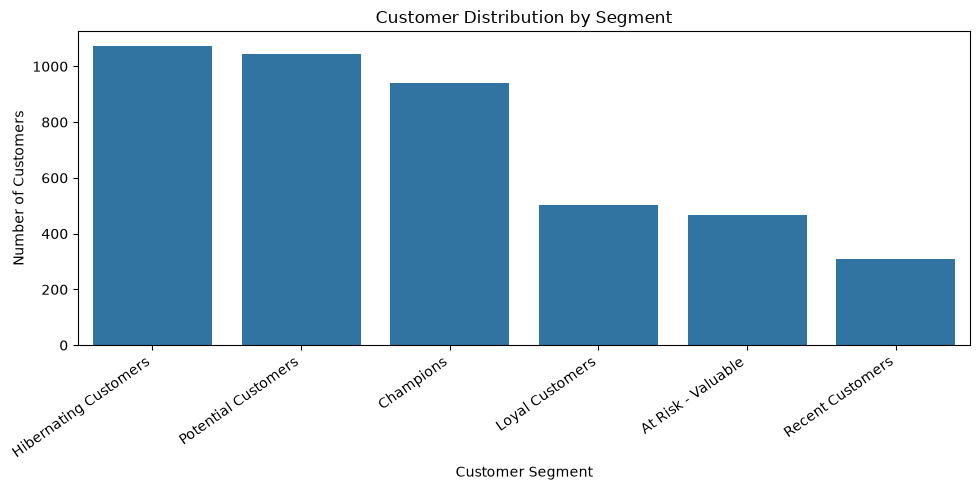

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=segment_summary,
    x="Segment",
    y="Customers"
)

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

**Prepare the data for Power BI**

In [ ]:
# Export customer-level RFM data
rfm.to_csv("customer_rfm_segments.csv", index=False)

# Export cleaned transaction data
df_clean.to_csv("cleaned_retail_transactions.csv", index=False)

print("Both CSV files exported successfully.")

Both CSV files exported successfully.


In [ ]:
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])
df_clean["YearMonth"] = df_clean["InvoiceDate"].dt.to_period("M").astype(str)
df_clean[["InvoiceDate", "YearMonth"]].head()

,InvoiceDate,YearMonth
0,2010-12-01 08:26:00,2010-12
1,2010-12-01 08:26:00,2010-12
2,2010-12-01 08:26:00,2010-12
3,2010-12-01 08:26:00,2010-12
4,2010-12-01 08:26:00,2010-12


In [ ]:
#Calculate monthly performance
monthly_sales = (
    df_clean.groupby("YearMonth").agg(
        Total_Sales=("TotalAmount", "sum"),
        Total_Orders=("InvoiceNo", "nunique"),
        Unique_Customers=("CustomerID", "nunique")
    )
    .reset_index()
)
monthly_sales

,YearMonth,Total_Sales,Total_Orders,Unique_Customers
0,2010-12,570422.730,1400,885
1,2011-01,568101.310,987,741
2,2011-02,446084.920,997,758
3,2011-03,594081.760,1321,974
4,2011-04,468374.331,1149,856
5,2011-05,677355.150,1555,1056
6,2011-06,660046.050,1393,991
7,2011-07,598962.901,1331,949
8,2011-08,644051.040,1280,935
9,2011-09,950690.202,1755,1266


Strong late-year performance: Sales increased from about £950,690 in September to £1.16 million in November.



November was the busiest month: It had the highest sales, order count and unique customer count in your results.



February was comparatively quiet: Sales were lower than in the surrounding months.



December 2011 needs careful interpretation: The dataset ends on December 9, so its sales total represents only a partial month. It should not be directly compared with complete months.

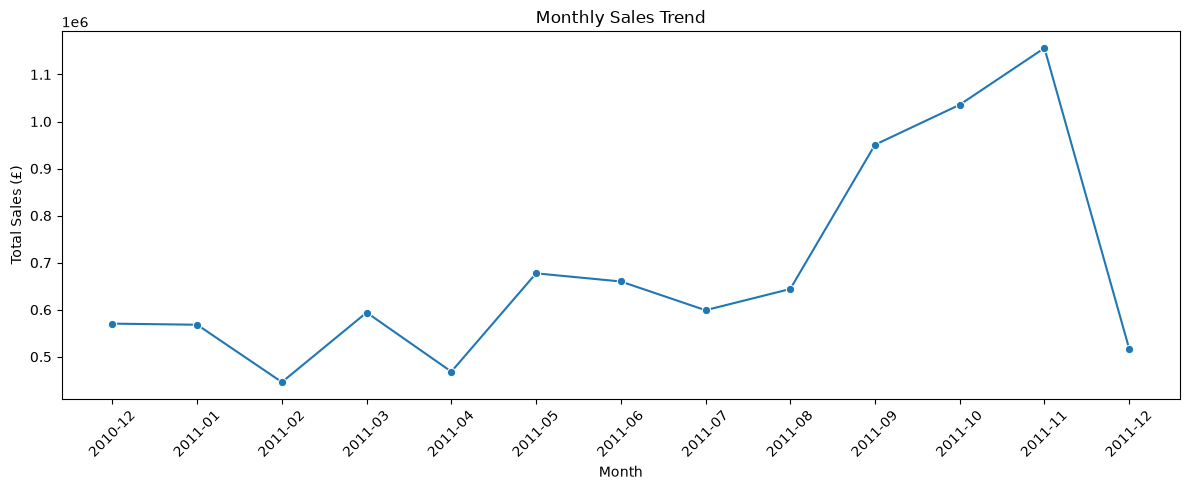

In [ ]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="Total_Sales",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

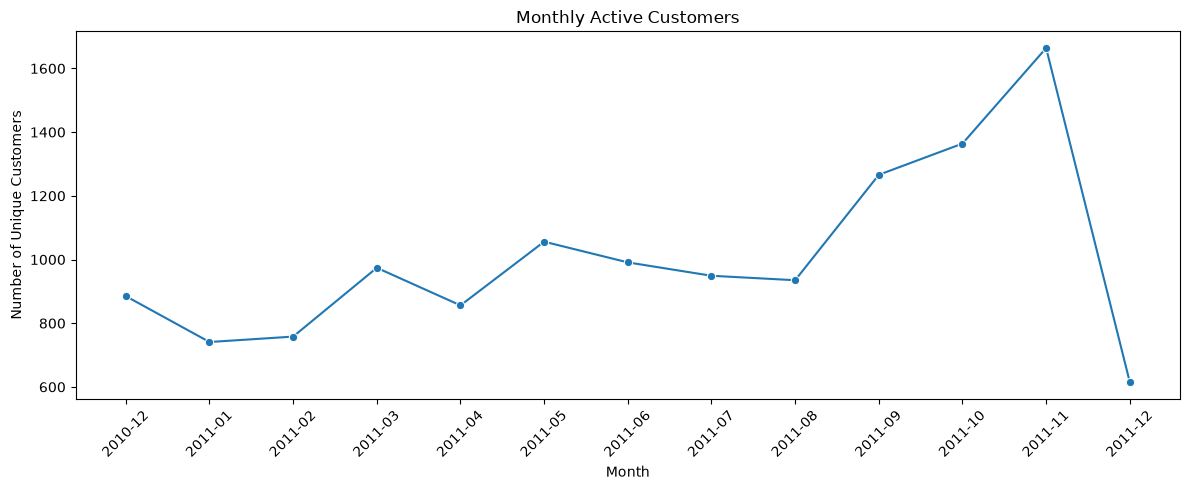

In [ ]:
#Plot monthly customer activity
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="Unique_Customers",
    marker="o"
)

plt.title("Monthly Active Customers")
plt.xlabel("Month")
plt.ylabel("Number of Unique Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**COHORT ANALYSIS**

Of the customers who first purchased in a particular month, how many returned in the following months?

In [37]:
df_clean["InvoiceMonth"] = (
    df_clean["InvoiceDate"].dt.to_period("M")
)

df_clean["CohortMonth"] = (
    df_clean.groupby("CustomerID")["InvoiceDate"]
    .transform("min")
    .dt.to_period("M")
)

df_clean[
    ["CustomerID", "InvoiceDate", "InvoiceMonth", "CohortMonth"]
].head()

,CustomerID,InvoiceDate,InvoiceMonth,CohortMonth
0,17850.0,2010-12-01 08:26:00,2010-12,2010-12
1,17850.0,2010-12-01 08:26:00,2010-12,2010-12
2,17850.0,2010-12-01 08:26:00,2010-12,2010-12
3,17850.0,2010-12-01 08:26:00,2010-12,2010-12
4,17850.0,2010-12-01 08:26:00,2010-12,2010-12


In [38]:
df_clean["CohortIndex"] = (
    (df_clean["InvoiceMonth"].dt.year - df_clean["CohortMonth"].dt.year) * 12
    + (df_clean["InvoiceMonth"].dt.month - df_clean["CohortMonth"].dt.month)
    + 1
)

df_clean[
    ["CustomerID", "InvoiceMonth", "CohortMonth", "CohortIndex"]
].head(10)

,CustomerID,InvoiceMonth,CohortMonth,CohortIndex
0,17850.0,2010-12,2010-12,1
1,17850.0,2010-12,2010-12,1
2,17850.0,2010-12,2010-12,1
3,17850.0,2010-12,2010-12,1
4,17850.0,2010-12,2010-12,1
5,17850.0,2010-12,2010-12,1
6,17850.0,2010-12,2010-12,1
7,17850.0,2010-12,2010-12,1
8,17850.0,2010-12,2010-12,1
9,13047.0,2010-12,2010-12,1


In [39]:
cohort_data = (
    df_clean.groupby(["CohortMonth", "CohortIndex"])["CustomerID"]
    .nunique()
    .reset_index()
)

cohort_counts = cohort_data.pivot(
    index="CohortMonth",
    columns="CohortIndex",
    values="CustomerID"
)

cohort_counts

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2010-12,885.0,324.0,286.0,340.0,321.0,352.0,321.0,309.0,313.0,350.0,331.0,445.0,235.0
2011-01,417.0,92.0,111.0,96.0,134.0,120.0,103.0,101.0,125.0,136.0,152.0,49.0,NaN
2011-02,380.0,71.0,71.0,108.0,103.0,94.0,96.0,106.0,94.0,116.0,26.0,NaN,NaN
2011-03,452.0,68.0,114.0,90.0,101.0,76.0,121.0,104.0,126.0,39.0,NaN,NaN,NaN
2011-04,300.0,64.0,61.0,63.0,59.0,68.0,65.0,78.0,22.0,NaN,NaN,NaN,NaN
2011-05,284.0,54.0,49.0,49.0,59.0,66.0,75.0,27.0,NaN,NaN,NaN,NaN,NaN
2011-06,242.0,42.0,38.0,64.0,56.0,81.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,188.0,34.0,39.0,42.0,51.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,169.0,35.0,42.0,41.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [41]:
#Calculate customer retention
# Get the number of customers in each cohort's first month
cohort_sizes = cohort_counts.iloc[:, 0]

# Calculate retention percentages
cohort_retention = cohort_counts.divide(cohort_sizes, axis=0) * 100

# Display percentages rounded to one decimal place
cohort_retention.round(1)

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2010-12,100.0,36.6,32.3,38.4,36.3,39.8,36.3,34.9,35.4,39.5,37.4,50.3,26.6
2011-01,100.0,22.1,26.6,23.0,32.1,28.8,24.7,24.2,30.0,32.6,36.5,11.8,NaN
2011-02,100.0,18.7,18.7,28.4,27.1,24.7,25.3,27.9,24.7,30.5,6.8,NaN,NaN
2011-03,100.0,15.0,25.2,19.9,22.3,16.8,26.8,23.0,27.9,8.6,NaN,NaN,NaN
2011-04,100.0,21.3,20.3,21.0,19.7,22.7,21.7,26.0,7.3,NaN,NaN,NaN,NaN
2011-05,100.0,19.0,17.3,17.3,20.8,23.2,26.4,9.5,NaN,NaN,NaN,NaN,NaN
2011-06,100.0,17.4,15.7,26.4,23.1,33.5,9.5,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,18.1,20.7,22.3,27.1,11.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.7,24.9,24.3,12.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


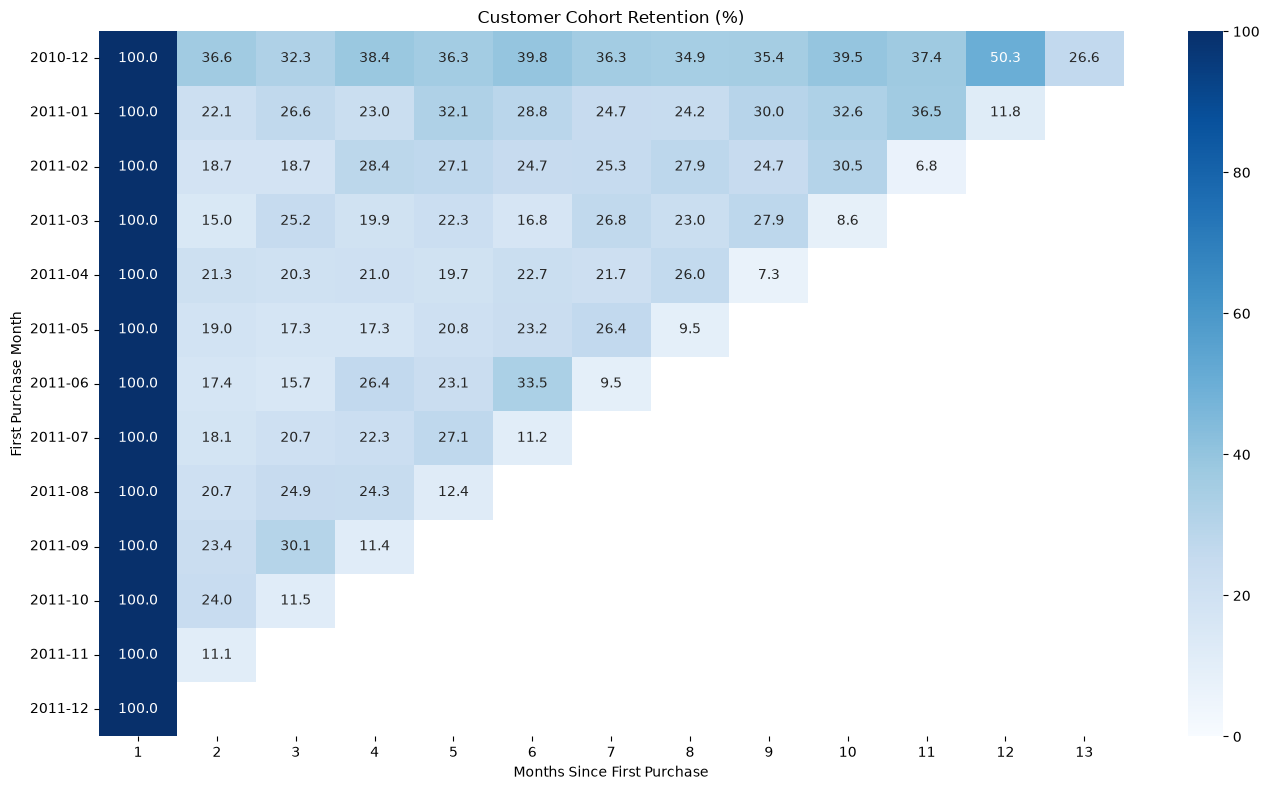

In [42]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    cohort_retention,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100
)

plt.title("Customer Cohort Retention (%)")
plt.xlabel("Months Since First Purchase")
plt.ylabel("First Purchase Month")
plt.tight_layout()
plt.show()

In [43]:
cohort_retention_export = cohort_retention.reset_index()

cohort_retention_export["CohortMonth"] = (
    cohort_retention_export["CohortMonth"].astype(str)
)

cohort_retention_export.to_csv(
    "customer_cohort_retention.csv",
    index=False
)

print("Cohort retention table exported successfully.")

Cohort retention table exported successfully.
